<a href="https://colab.research.google.com/github/aishwaryaaramanathan/DL_Lab_241501011/blob/main/dl_exp_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision.utils import save_image

In [2]:
# Clone StyleGAN2-ADA
if not os.path.exists("stylegan2-ada-pytorch"):
    !git clone https://github.com/NVlabs/stylegan2-ada-pytorch.git

%cd stylegan2-ada-pytorch

Cloning into 'stylegan2-ada-pytorch'...
remote: Enumerating objects: 131, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 131 (delta 0), reused 0 (delta 0), pack-reused 129 (from 2)
Receiving objects: 100% (131/131), 1.13 MiB | 11.81 MiB/s, done.
Resolving deltas: 100% (57/57), done.
/content/stylegan2-ada-pytorch


In [3]:
# Download pretrained model
if not os.path.exists("ffhq.pkl"):
    !wget -q https://nvlabs-fi-cdn.nvidia.com/stylegan2-ada-pytorch/pretrained/ffhq.pkl

import legacy
import dnnlib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Load generator
with open("ffhq.pkl", "rb") as f:
    G = legacy.load_network_pkl(f)["G_ema"].to(device)

In [5]:
# Generate image
os.makedirs("generated_images", exist_ok=True)

z = torch.randn(1, G.z_dim, device=device)
label = torch.zeros(1, G.c_dim, device=device)

with torch.no_grad():
    img = G(z, label, truncation_psi=0.7, noise_mode="const")

img = (img + 1) / 2
save_image(img.clamp(0, 1), "generated_images/fake.png")

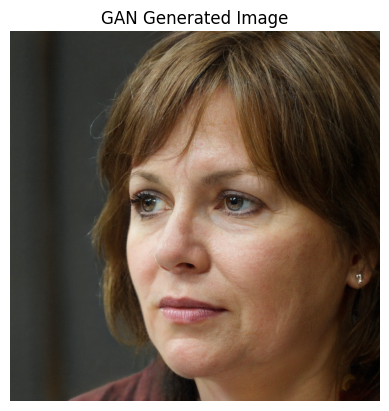

In [6]:
# Display image
plt.imshow(Image.open("generated_images/fake.png"))
plt.axis("off")
plt.title("GAN Generated Image")
plt.show()